In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
import math

/home/bhanselman/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
pvals = np.load('/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/analyses/20261022/exclusion/decay/0/pvals/uninj_int_pvals.npy')
pvals

array([[7.51557827e+02, 7.51740932e+02, 7.51924038e+02, ...,
        2.25100851e+03, 2.25119162e+03, 2.25137472e+03],
       [4.96163342e-01, 4.92808492e-01, 4.92765380e-01, ...,
        5.15782263e-01, 5.29455020e-01, 5.36814790e-01]])

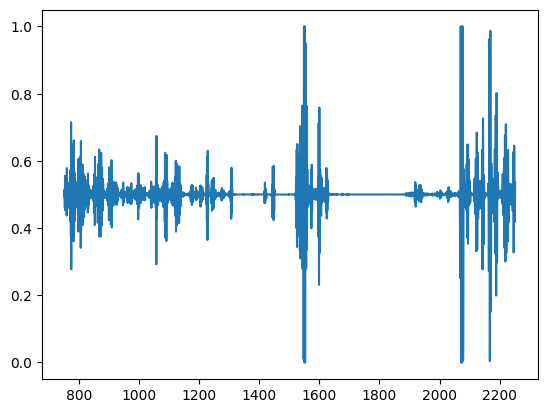

In [3]:
plt.plot(*pvals)

In [4]:
asym_1 = np.load('/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/analyses/20261022/target_selection/20261022/decay/0/intensity/best_asymmetry.npy')

In [5]:
asym_1

array([[ 751.557827  ,  751.74093246,  751.92403793, ..., 2251.00851059,
        2251.19161606, 2251.37472153],
       [          nan,           nan,           nan, ...,           nan,
                  nan,           nan]])

In [8]:
uninj_norm_spectra = np.load('/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/analyses/20261022/exclusion/decay/0/uninj_norm_spectra.npy')

info = pd.read_csv('/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/all_lscx_info.csv', sep='\t')
bank_dir = '/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/data/preprocessed/0'
bank_info = info[info['time'].apply(lambda l: l + '.npy').isin(os.listdir(bank_dir))]

# Optimized states
state_int_all = np.load('/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/analyses/20261022/target_selection/20261022/decay/0/intensity/best_state.npy')
state_dopp_all = np.load('/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/analyses/20261022/target_selection/20261022/decay/0/doppler/best_state.npy')
# Exclude the spectra appearing in neither state, and prepare states/masks for asymmetry formation
state_mask = (state_int_all == 1) | (state_dopp_all == 1)
bank_info = bank_info[state_mask]
targs = bank_info['time'].apply(lambda l: l + '.npy')
state_int, state_dopp = state_int_all[state_mask], state_dopp_all[state_mask]
int_mask = (bank_info['phi'] < 90).to_numpy()
dopp_mask = (bank_info['theta'] < 90).to_numpy()

def build_asymmetry(specs, state, mask, time_mask=None):
    '''Form asymmetry from a given state.'''

    if time_mask is not None:
        inner_mean_pre = np.nanmean(specs[(state == 1) & mask & time_mask], axis=0)
        inner_mean_post = np.nanmean(specs[(state == 1) & mask & ~time_mask], axis=0)
        outer_mean_pre = np.nanmean(specs[(state == 1) & ~mask & time_mask], axis=0)
        outer_mean_post = np.nanmean(specs[(state == 1) & ~mask & ~time_mask], axis=0)

        asymmetry = (inner_mean_pre + inner_mean_post - outer_mean_pre - outer_mean_post) / (inner_mean_pre + inner_mean_post + outer_mean_pre + outer_mean_post)

    else:
        inner_mean = np.nanmean(specs[(state == 1) & mask], axis=0)
        outer_mean = np.nanmean(specs[(state == 1) & ~mask], axis=0)

        asymmetry = (inner_mean - outer_mean) / (inner_mean + outer_mean)

    return asymmetry

asym_2 = build_asymmetry(uninj_norm_spectra, state_int, int_mask)

In [9]:
asym_2

array([0., 0., 0., ..., 0., 0., 0.])

(-1e-06, 1e-06)

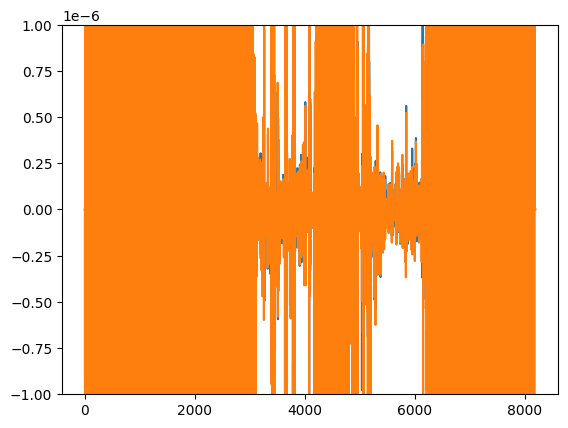

In [13]:
plt.plot(asym_1[1])
plt.plot(asym_2)
plt.ylim(-1e-6, 1e-6)

# Correlation

In [14]:
def correlate_asymmetry(freqs, template_xs, spectrum, template):
    # def stretch_template(template, stretch_factor):
    #     if template.shape[0] % 2 == 0:
    #         template = template[1:] # Make the number of points odd
    #     k = template.shape[0] // 2
    #     orig_x = np.arange(-k, k+1)
    #     interp_func = interp1d(orig_x, template, bounds_error=False, fill_value=0)
    #     new_k = ((2*k + 1)/stretch_factor - 1)/2 # 2k_1 + 1 = sf*(2k_0 + 1)
    #     new_x = np.linspace(-new_k, new_k, template.shape[0])

    #     return interp_func(new_x)

    def get_a(target, template):
        return np.dot(target, template) / (np.dot(template, template) + 1e-12)
    
    a_vals = np.zeros_like(spectrum)

    for i in range(len(spectrum)):
        ref_freq = freqs[i]
        xs_shift = ref_freq * template_xs
        width = 3 * factor * ref_freq // freq_diff
        new_xs = np.arange(-width, width+1) * freq_diff + ref_freq
        stretched = np.interp(new_xs, xs_shift, template)
        
        lower = (len(stretched) - 1) // 2
        upper = (len(stretched) + 1) // 2

        if i < lower:
            x = lower - i
            stretched = stretched[x:]
            window = spectrum[:i+upper]
        elif i > (len(spectrum) - upper):
            x = len(spectrum) - upper - i
            stretched = stretched[:x]
            window = spectrum[i-lower:]
        else:
            window = spectrum[i-lower:i+upper]
        
        a = get_a(window, stretched) 
        a_vals[i] = a 

    return a_vals

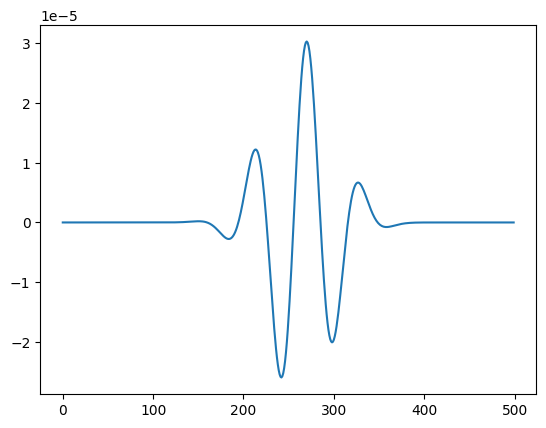

In [15]:
template_spectra = np.load('/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/analyses/20261022/exclusion/decay/0/template_spectra.npy')
temp_asym = build_asymmetry(template_spectra, state_int, int_mask)
plt.plot(temp_asym)

(5500.0, 5800.0)

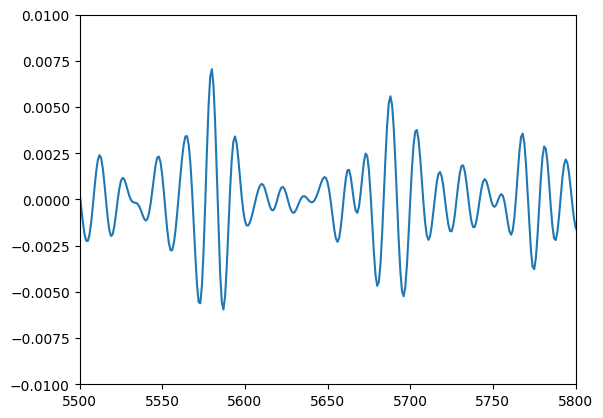

In [34]:
num = 3
c = 299792
v_virial = 250 # km/s
v_earth = 225 # km/s
factor = v_earth / c + (v_virial / (c*np.sqrt(num)) * 3) * (1 + v_earth / c)

template_xs = np.linspace(1-3*factor, 1+3*factor, 500)

xs = np.load('/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/data/preprocessed/0/57507_59078.npy')[0]
freq_diff = 1500 / 8192

corr_int = correlate_asymmetry(xs, template_xs, asym_2, temp_asym)

plt.plot(corr_int)
plt.ylim(-0.01,0.01)
plt.xlim(5500,5800)

In [ ]:
6 * factor * xs[0] / freq_diff

54.08053941052856

In [27]:
def get_pvals_cont(inj, uninj, freqs):
    stds = np.zeros_like(uninj)
    for i in range(len(uninj)):
        window_half_size = int(6 * factor * freqs[i] / freq_diff)
        if i < window_half_size:
            slice = uninj[:i+window_half_size+1]
        elif i >= len(uninj) - window_half_size:
            slice = uninj[i-window_half_size:]
        else:
            slice = uninj[i-window_half_size:i+window_half_size+1]

        stds[i] = np.nanstd(slice)
    
    sigmas = inj / stds
    pvals = list(map(lambda sigma: .5*math.erfc(sigma/np.sqrt(2)), sigmas))
    return pvals

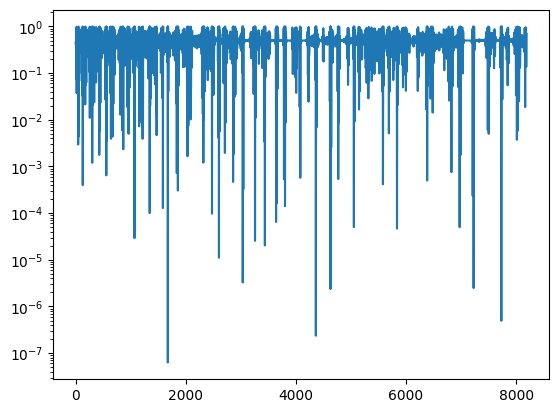

In [32]:
pvals = get_pvals_cont(corr_int, corr_int, xs)
plt.plot(pvals)
plt.yscale('log')

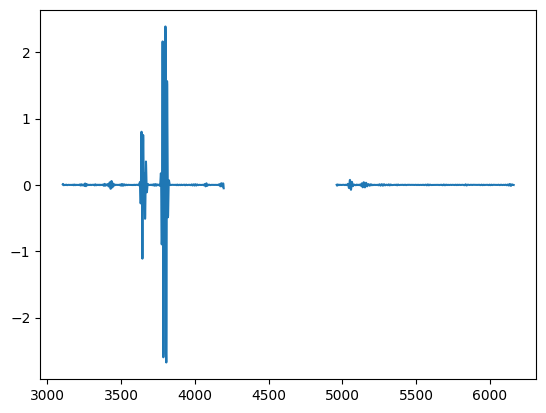

In [35]:
# Now, I'll try pvals w/ blanking ranges.
blanking_ranges = [
    (750, 1320),
    (1520, 1660),
    (1880, 2260)
]

condition = np.any(
    [
        (xs > blank[0]) & (xs < blank[1])
        for blank in blanking_ranges
    ],
    axis=0
)

corr_int_blank = np.where(condition, np.nan, corr_int)
plt.plot(corr_int_blank)

/home/bhanselman/anaconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


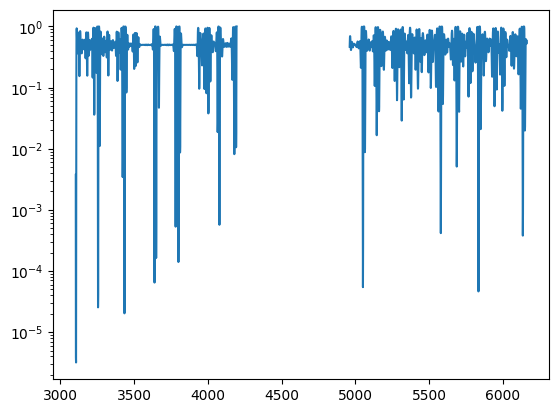

In [37]:
pvals_blank = get_pvals_cont(corr_int_blank, corr_int_blank, xs)
plt.plot(pvals_blank)
plt.yscale('log')

# Heatmap investigation

In [2]:
uninj_norm_spectra = np.load('/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/analyses/20261022/exclusion/decay/0/uninj_norm_spectra.npy')

info = pd.read_csv('/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/all_lscx_info.csv', sep='\t')
bank_dir = '/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/data/preprocessed/0'
bank_info = info[info['time'].apply(lambda l: l + '.npy').isin(os.listdir(bank_dir))]

# Optimized states
state_int_all = np.load('/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/analyses/20261022/target_selection/20261022/decay/0/intensity/best_state.npy')
state_dopp_all = np.load('/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/analyses/20261022/target_selection/20261022/decay/0/doppler/best_state.npy')
# Exclude the spectra appearing in neither state, and prepare states/masks for asymmetry formation
state_mask = (state_int_all == 1) | (state_dopp_all == 1)
bank_info = bank_info[state_mask]
targs = bank_info['time'].apply(lambda l: l + '.npy')
state_int, state_dopp = state_int_all[state_mask], state_dopp_all[state_mask]
int_mask = (bank_info['phi'] < 90).to_numpy()
dopp_mask = (bank_info['theta'] < 90).to_numpy()

xs = np.load('/home/dataadmin/GBTData/SharedDataDirectory/lscx_081526/data/preprocessed/0/57507_59078.npy')[0]

In [11]:
from matplotlib.figure import Figure
from astropy.visualization import ZScaleInterval
from matplotlib.colors import Normalize

def plot_heatmaps(freq=None, n_bins=50, resid=False, fig=None):
    if freq:
        mask = (xs >= freq-50) & (xs < freq+50)
    else:
        mask = np.full(xs.shape, True)

    nans = np.full(xs.shape, np.nan)[mask]

    bank_info['time_mjd'] = bank_info['time'].apply(lambda mjd: int(mjd.split('_')[0])) #[int(mjd.split('_')[0]) for mjd in info['time']]
    bank_info['cos_theta'] = bank_info['theta'].apply(lambda theta: math.cos(math.radians(theta))) #[math.cos(math.radians(theta)) for theta in info['theta']]
    bank_info['cos_phi'] = bank_info['phi'].apply(lambda phi: math.cos(math.radians(phi))) #[math.cos(math.radians(phi)) for phi in info['phi']]

    var_list = ['cos_theta', 'cos_phi', 'time_mjd']

    if fig is None:
        fig = Figure(figsize=(18, 18))
    axs = fig.subplots(3, 1)

    def create_map(bin_column, cond):
        for i in range(n_bins):
            bin_mask = cond & (bank_info[bin_column] == i).to_numpy()
            spectra = uninj_norm_spectra[bin_mask][:, mask]
            if spectra.size:
                avg = np.nanmean(spectra, axis=0)
                yield avg
            else:
                yield nans

    for i, var in enumerate(var_list):
        bounds = (min(bank_info['time_mjd']), max(bank_info['time_mjd'])) if var == 'time_mjd' else (-1, 1)
        bins = np.linspace(*bounds, n_bins+1)
        bank_info[f'{var}_bin'] = pd.cut(bank_info[var], bins, labels=False)

        if var == 'cos_theta':
            state = state_dopp
            label = r'$\mathrm{cos}({\theta})$'
        elif var == 'cos_phi':
            state = state_int
            label = r'$\mathrm{cos}({\phi})$'
        else:
            state = np.ones(uninj_norm_spectra.shape[0])
            label = 'Modified JD'
            
        heat_map = np.array(list(create_map(f'{var}_bin', state == 1)))
        if resid:
            heat_map = heat_map - np.nanmean(uninj_norm_spectra[state == 1][:, mask], axis=0)

        ax = axs[i]
        interval = ZScaleInterval()
        vmin, vmax = interval.get_limits(np.array(heat_map))
        if resid:
            vmax = max(vmax, -vmin)
            ndigits = -int(math.floor(math.log10(vmax))) + 1
            vmax = round(vmax, ndigits)
            vmin = -vmax
        else:
            vmax = max(vmax, 2-vmin)
            ndigits = -int(math.floor(math.log10(vmax - 1))) + 1
            vmax = round(vmax, ndigits)
            vmin = 2 - vmax
        norm = Normalize(vmin=vmin, vmax=vmax)
        extent = [np.min(xs[mask]), np.max(xs[mask]), *bounds]

        im1 = ax.imshow(heat_map, extent=extent, cmap='RdBu' if resid else 'viridis', origin='lower', norm=norm, aspect='auto', interpolation='none')

        ax.set_ylabel(label, fontsize=18)

        if var != 'time_mjd':
            #ax.axhline(0, c='r') # Inward/outward division
            ax.set_yticks(np.linspace(-1, 1, 5))

    fig.suptitle(f'Heatmaps', fontsize=20)

    axs[-1].set_xlabel(r'$\nu$ [MHz]', fontsize=18)

    cbar = fig.colorbar(im1, ax=axs.ravel().tolist(), orientation='horizontal', fraction=0.0335, pad=0.04)
    cbar.set_label('Normalized Power Residual' if resid else 'Normalized Power', fontsize=18)
    
    return fig

In [12]:
%matplotlib inline

/tmp/ipykernel_1323797/2242997759.py:28: RuntimeWarning: Mean of empty slice
  avg = np.nanmean(spectra, axis=0)


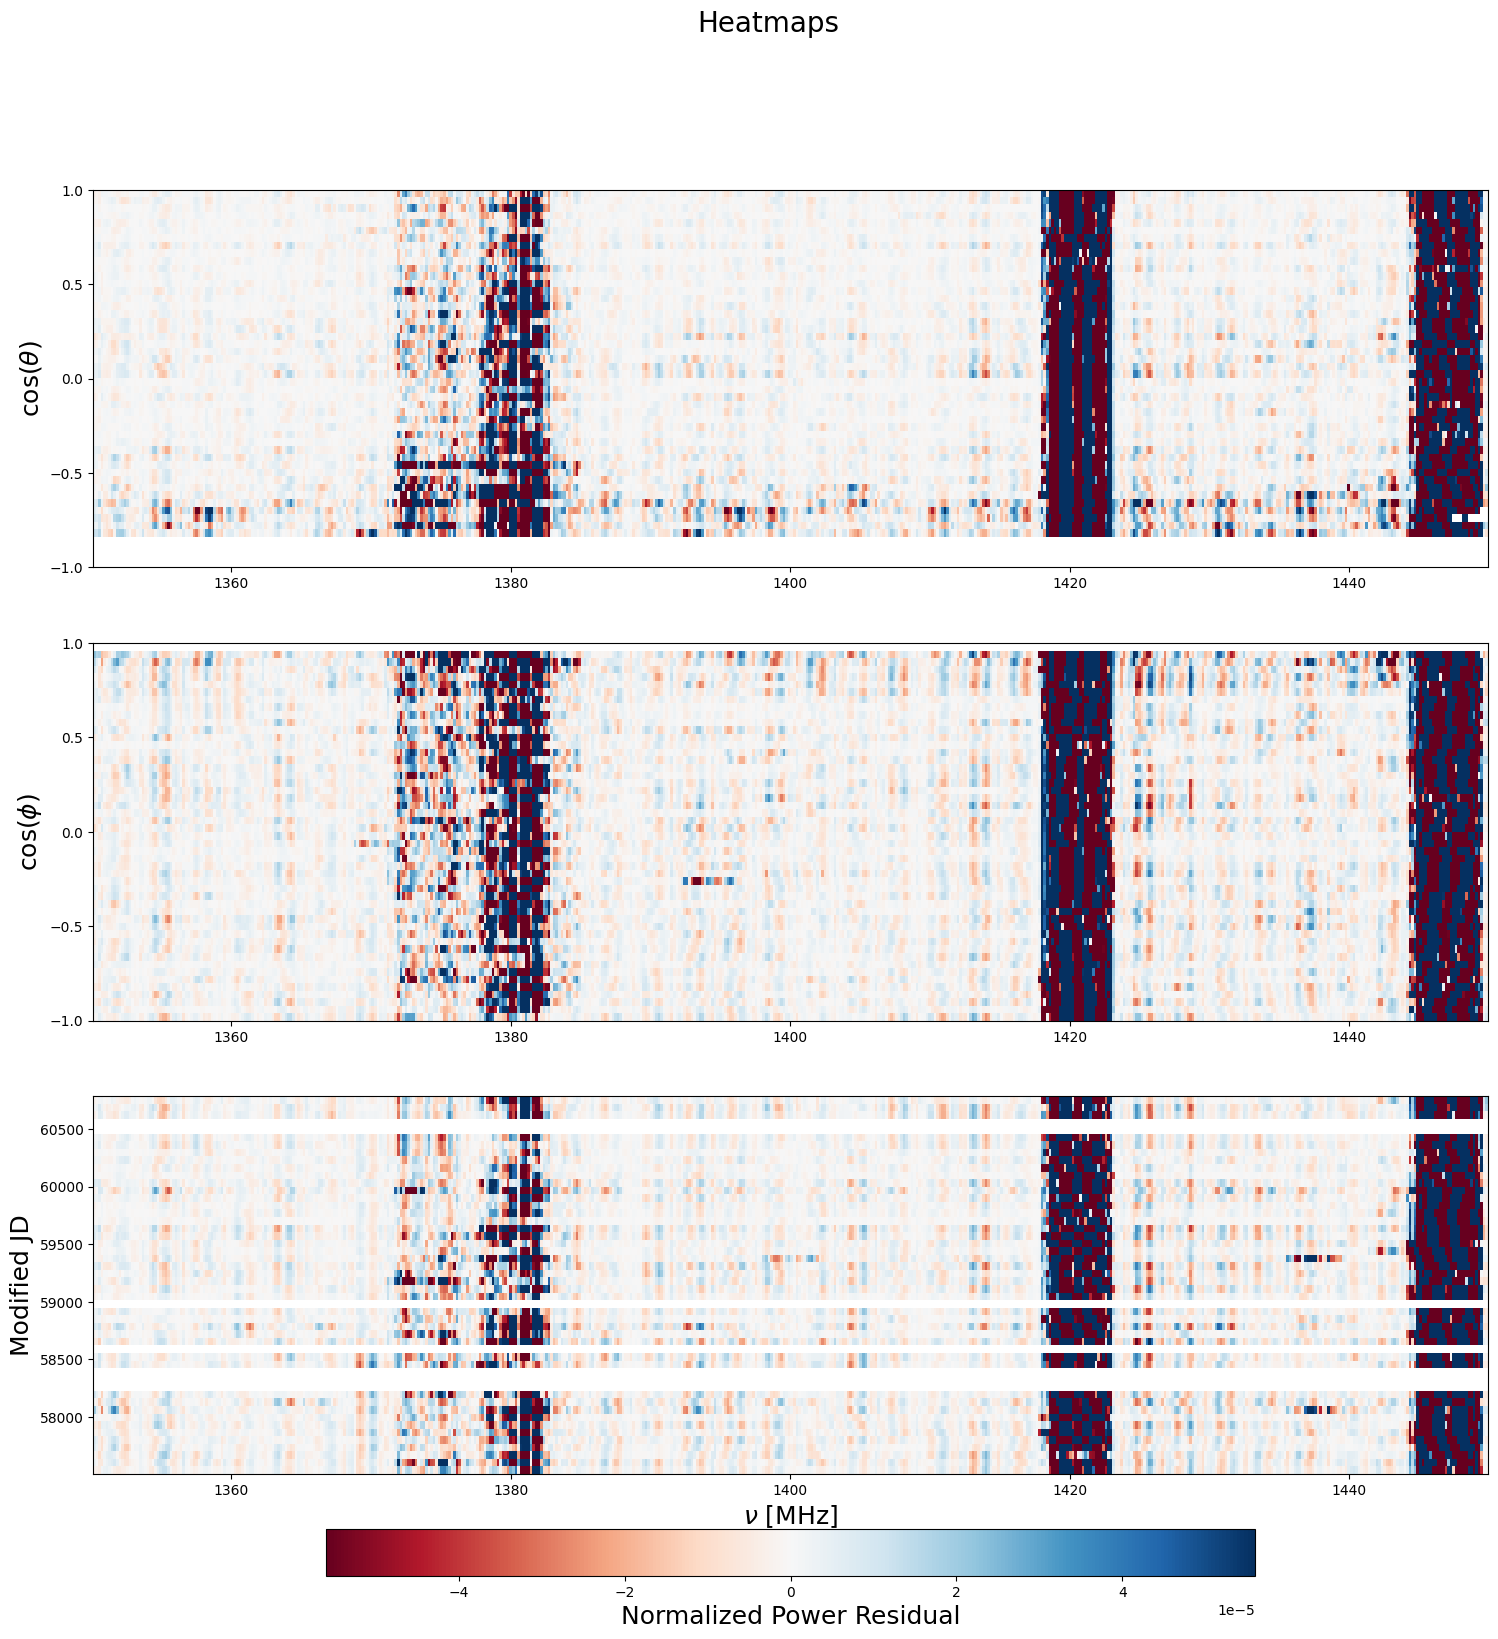

In [13]:
plot_heatmaps(freq=1400, resid=True)

In [6]:
len(uninj_norm_spectra), len(bank_info)

(5976, 5976)

In [8]:
def convert_to_seconds(l):
    mjd, seconds = l.split('_')
    mjd, seconds = int(mjd), int(seconds)
    return mjd * 86400 + seconds

bank_info['time'].apply(convert_to_seconds)

1039     4968663878
1040     4968664222
1046     4968666267
1047     4968666606
1048     4968666938
            ...    
57400    5251958900
57406    5251962807
57408    5251964115
57409    5251964776
57412    5251966093
Name: time, Length: 5976, dtype: int64

(array([960.,  61., 251., 181.,  41.,  53., 207.,  78.,  40.,   8.,  24.,
          0.,   0.,   0.,  14.,  20.,   0.,  31.,  81.,   3.,  34.,  61.,
          0.,  89.,  40.,  41.,  80.,  54.,  97., 146.,  54.,  35.,  83.,
        205., 105., 254., 240.,  27.,  29., 310., 230., 406., 187., 232.,
        251.,  12.,   0., 110., 272., 239.]),
 array([4.96866388e+09, 4.97432992e+09, 4.97999597e+09, 4.98566201e+09,
        4.99132806e+09, 4.99699410e+09, 5.00266014e+09, 5.00832619e+09,
        5.01399223e+09, 5.01965828e+09, 5.02532432e+09, 5.03099037e+09,
        5.03665641e+09, 5.04232245e+09, 5.04798850e+09, 5.05365454e+09,
        5.05932059e+09, 5.06498663e+09, 5.07065268e+09, 5.07631872e+09,
        5.08198476e+09, 5.08765081e+09, 5.09331685e+09, 5.09898290e+09,
        5.10464894e+09, 5.11031499e+09, 5.11598103e+09, 5.12164707e+09,
        5.12731312e+09, 5.13297916e+09, 5.13864521e+09, 5.14431125e+09,
        5.14997730e+09, 5.15564334e+09, 5.16130938e+09, 5.16697543e+09,
        5.

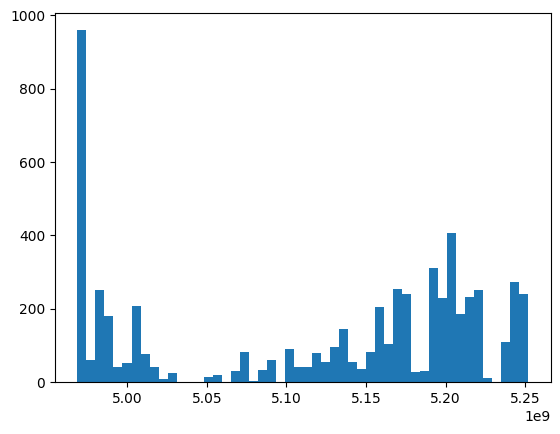

In [10]:
plt.hist(bank_info['time'].apply(convert_to_seconds), bins=50)